In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from gliders.utils import sigma_clipping, grow_mask, get_profile_from_border, normalize_data
from gliders.artifacts import detect_artifacts, get_artifact_flag, clean_artifacts, detect_and_clean_artifacts
from gliders.background_suppressor import suppress_background, show_all_methods
from scipy.stats import norm
from scipy.signal import convolve2d
from astropy.convolution import Gaussian2DKernel
import warnings
from astropy.utils.exceptions import AstropyDeprecationWarning
from photutils.utils.exceptions import NoDetectionsWarning
warnings.simplefilter('ignore', category=AstropyDeprecationWarning)
warnings.simplefilter('ignore', category=NoDetectionsWarning)

def extract_band_data(hdu_list, verbose=True, bands_to_analyze = ['r']):
    all_bands = {}
    all_img_diffs = {}
    all_img_areas = {}
    all_weights = {}
    all_wgh_diffs = {}
    all_wgh_areas = {}
    ref_hdu = None
    for hdu in hdu_list:
        try:
            header = hdu._header
            if verbose:
                print(header)
            band = header.get("BAND")
            if band not in bands_to_analyze: continue
            image_type = header.get("IMAGETYP")
            imagew = header.get("IMAGEW")
            imageh = header.get("IMAGEH")

            if band is None or image_type is None or imagew is None or imageh is None:
                continue  # Skip if essential header info is missing

            img_dim_diff = abs(imagew - imageh)
            img_area = imagew * imageh

            if image_type == "image":
                if band not in all_bands or img_area > all_img_areas[band] or (img_area == all_img_areas[band] and img_dim_diff < all_img_diffs[band]):
                    all_bands[band] = hdu.copy().data
                    all_img_areas[band] = img_area
                    all_img_diffs[band] = img_dim_diff
                    ref_hdu = hdu.header

            elif image_type == "invvar":
                w_map = hdu.copy().data
                w_map[w_map == 0] += 1  # Avoid division by zero
                weight = 1 / np.sqrt(w_map)
                if band not in all_weights or img_area > all_wgh_areas[band] or (img_area == all_wgh_areas[band] and img_dim_diff < all_wgh_diffs[band]):
                    all_weights[band] = weight
                    all_wgh_areas[band] = img_area
                    all_wgh_diffs[band] = img_dim_diff

        except Exception as e:
            print(f"Skipped HDU due to error: {e}")

    return all_bands, all_weights, ref_hdu

file_dir = "C:/Astrostuff/PhD/Data/DESI FITS/"
artif_file = "D:/Astrostuff/PhD/Data/My_data/DESI_New_mergers.csv"
artif_catalog = Table.read(artif_file, format = "csv", converters = {"object_id":str})
print(len(artif_catalog))
print(artif_catalog)

3754
    object_id         ra      dec       z    ...    I    merger_predicted  ES
----------------- --------- -------- ------- ... ------- ---------------- ---
39627902957912363 211.09828  4.71795 0.02977 ... 0.41312                1   1
39632991730798910 253.11914 35.41754 0.05766 ...  0.2024                1   1
39627829528234714 150.37899  1.68886 0.09869 ... 0.01352                1   1
39627830664894213  218.2308  1.86938 0.02998 ... 0.58443                1   1
39633427988745611 271.28566 63.42304  0.0915 ...  0.2459                1   1
39627758090851335  212.4838 -1.23884  0.0248 ... 0.47045                1   1
39633104083616306 152.75604 41.58966 0.05861 ... 0.60419                1   1
39627877821449269 150.00236  3.67734 0.07391 ... 0.03693                1   1
39627773882401920   73.5449 -0.39993 0.05467 ... 0.15411                1   1
39633321931571417 185.66454 55.08292 0.03664 ... 0.28208                1   1
              ...       ...      ...     ... ...     ...   

0 39627817436057197
1 39633293271894039
2 39627770304661746


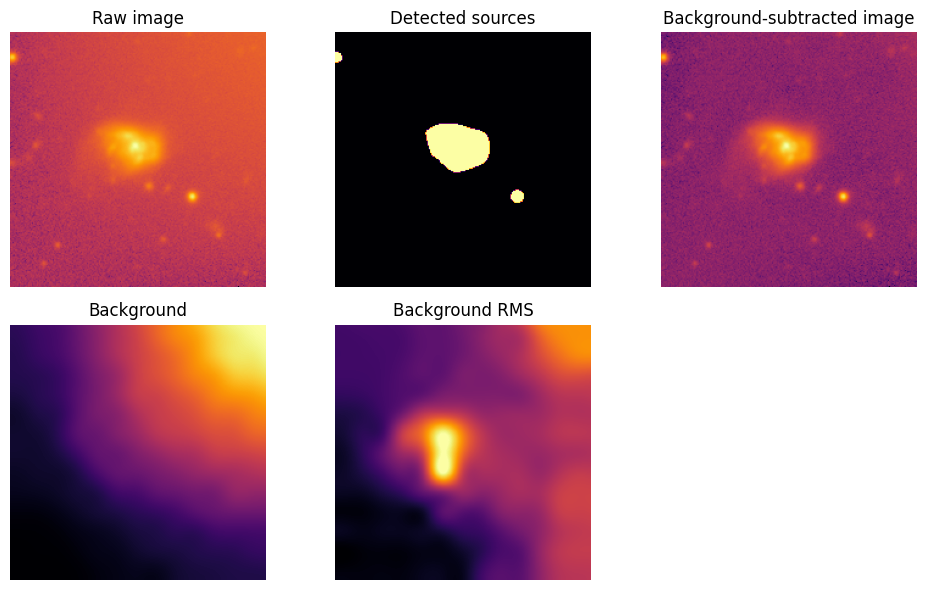

3 39628427904418064
4 39633293347391690


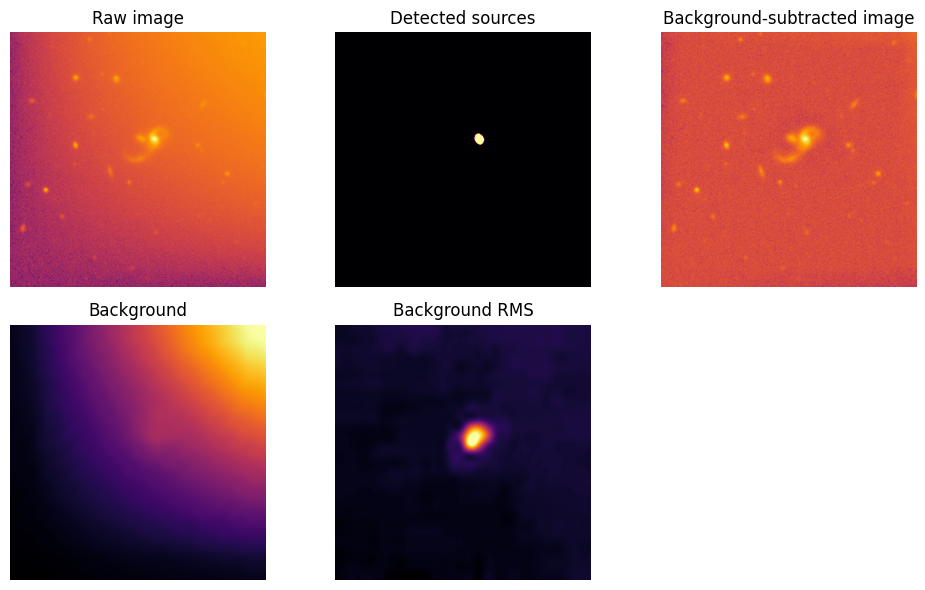

5 39627811408841508


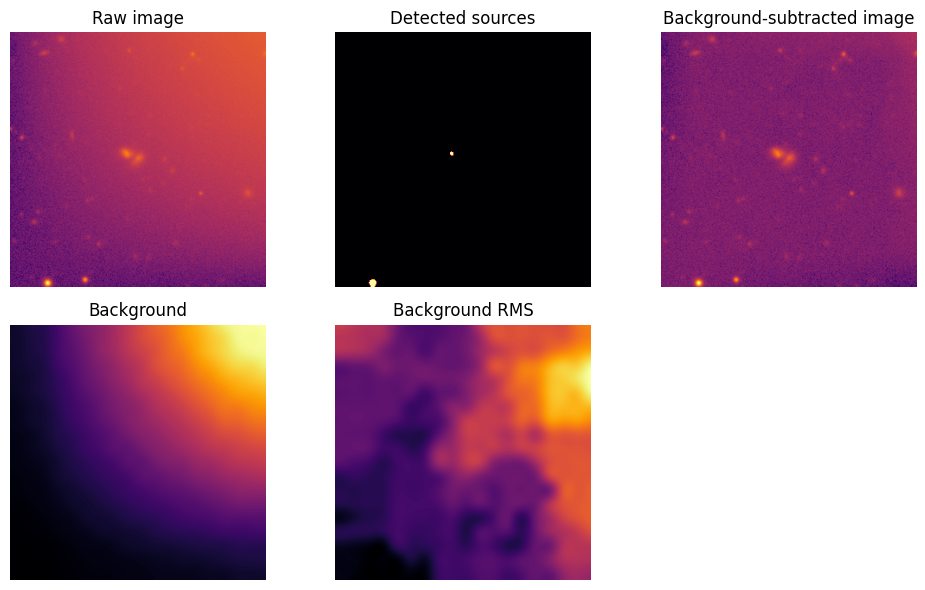

6 39627890869931123


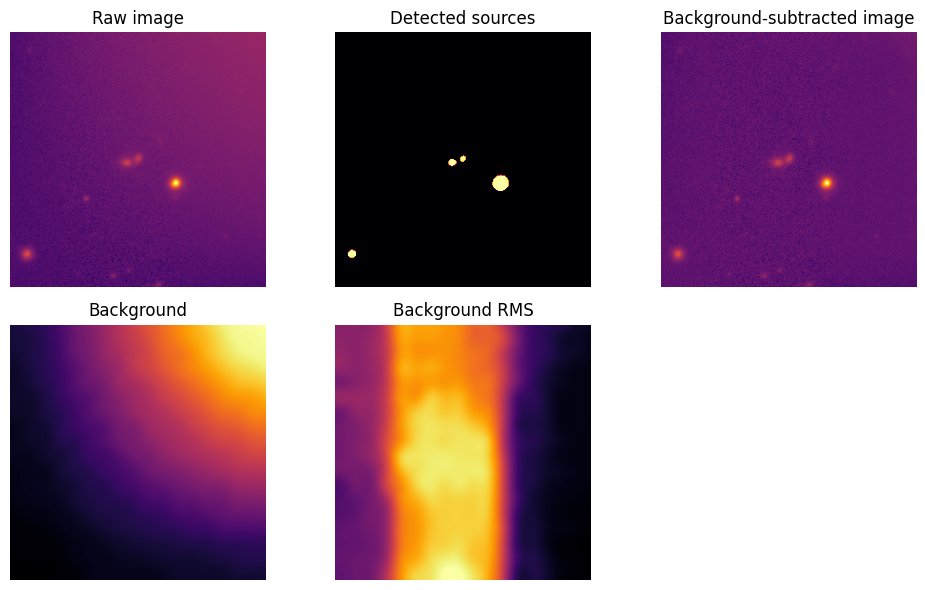

7 39628427887641099


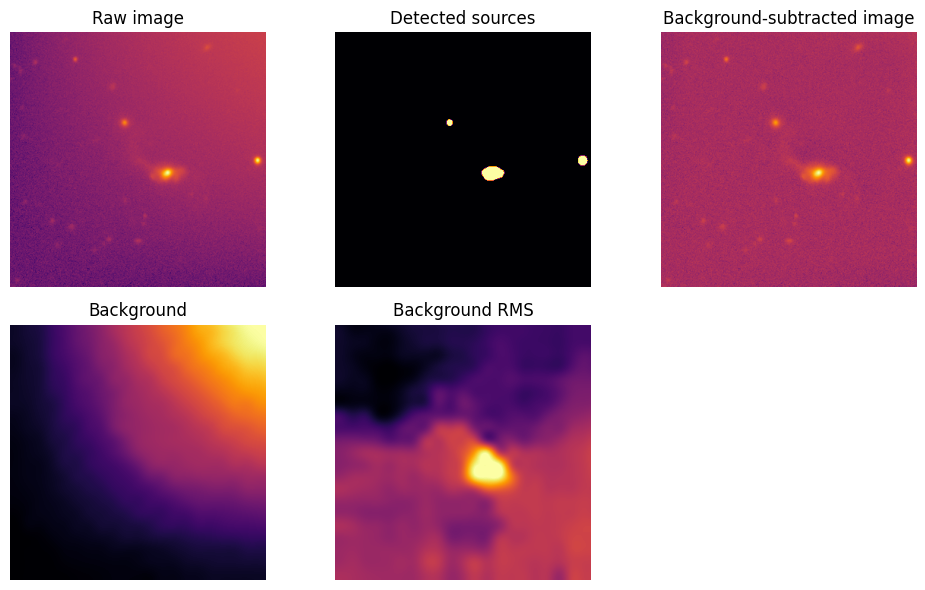

8 39633393155049991


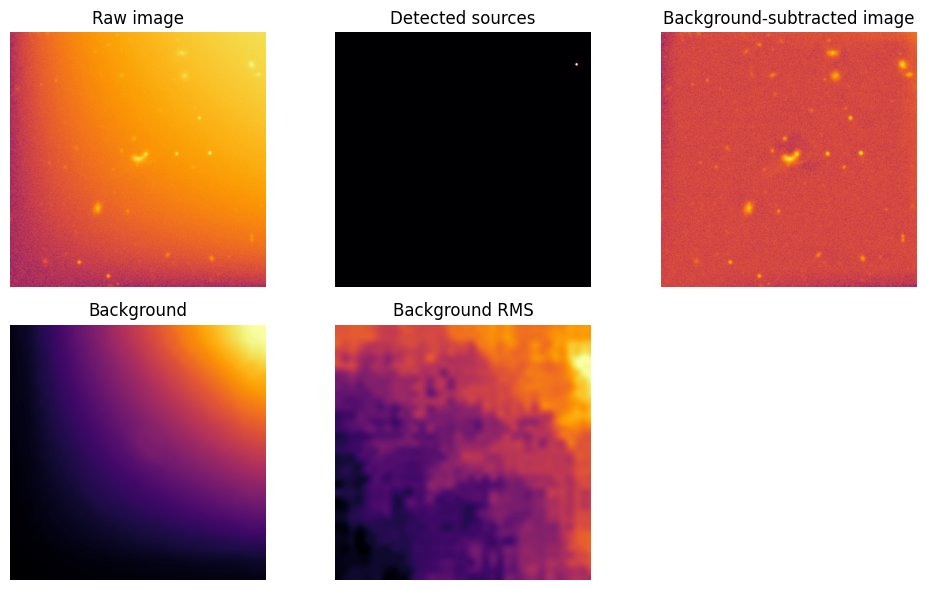

9 39633345725857934


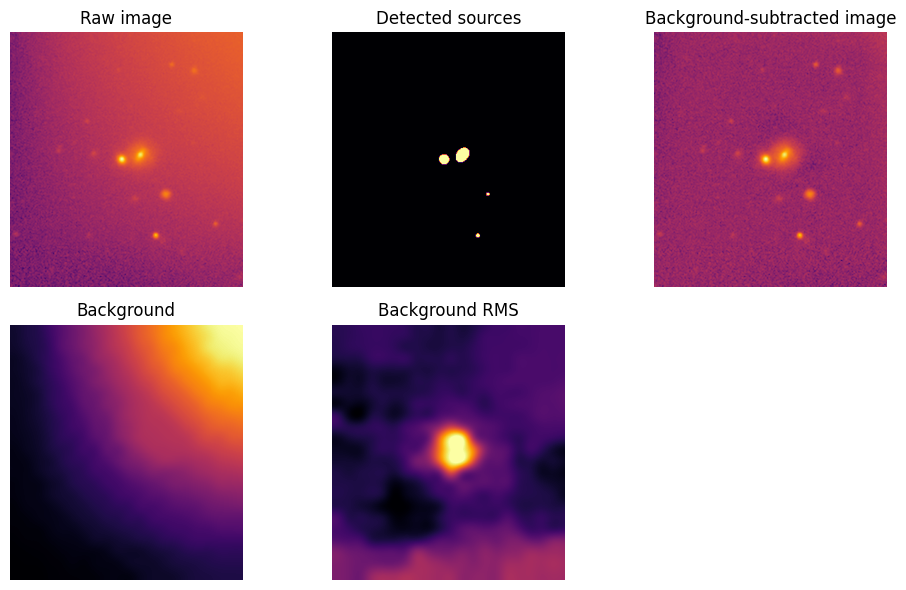

10 39633127575915118
11 39627740038567631


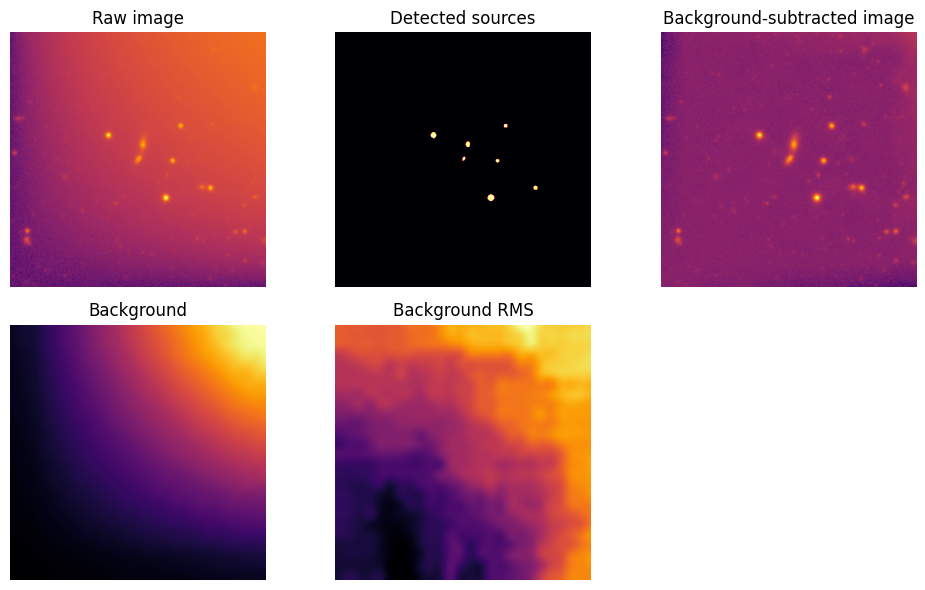

DONE!


In [278]:
bleed_radii = []
areas = []
from gliders.cleaning_configs import configs
config = configs["default"]
for ii, object_info in enumerate(artif_catalog[140:]):
    object_id = object_info[0]
    print(ii, object_id)
    obj_coords = (object_info[1],object_info[2])
    redshift = object_info[3]
    bands = ['r'] #,'g']
    file_name = f"{object_id}_{"".join(bands)}.fits"
    sources_name = f"{object_id}_sources.fits"

    file_path = os.path.join(file_dir, file_name)
    sources_path = os.path.join(file_dir, sources_name)
    try:
        with fits.open(file_path) as hdu_list:
            # hdu_list.info()
            all_bands, all_weights, ref_header = extract_band_data(hdu_list, verbose=False, bands_to_analyze=bands)
    except:
        continue

    with fits.open(sources_path) as hdul:
        data = hdul[1].data
        as_table = Table(data)
    wcs = WCS(ref_header)
    tractor_x_pix, tractor_y_pix = wcs.all_world2pix(as_table['ra'], as_table['dec'], 0)  # origin=0 for Python indexing
    source_x_pix, source_y_pix = wcs.all_world2pix(obj_coords[0], obj_coords[1], 0)  # origin=0 for Python indexing
    source_pos = (np.round(source_x_pix), np.round(source_y_pix))
    as_table['x_centroid'] = tractor_x_pix
    as_table['y_centroid'] = tractor_y_pix
    phot_sources = as_table['type','x_centroid','y_centroid']
    image = all_bands['r']


    if obj_coords[1] > 32.375:
        pix_scale = 1.72
    else:
        pix_scale = 1

    from photutils.segmentation import SourceCatalog, detect_threshold, detect_sources
    # from gliders.background_suppressor import suppress_background
    from gliders.others import remove_low_outliers, segmentation_map_smoothing, clear_background, mask_secondary_detections, flatten_background, mask_secondary_detections
    source_min_pix = 10
    # image = suppress_background(image, method = "layers")
    from gliders.pipeline import update_detections
    from gliders.utils import convolve_with_gaussian_kernel, smooth_blend
    from photutils.segmentation import SegmentationImage
    from astropy.stats import SigmaClip
    from photutils.background import Background2D,  MedianBackground, MeanBackground, SExtractorBackground, MADStdBackgroundRMS

    # image = suppress_background(image, method = "layers")
    # image_u, seg_map, main_source_segmap = update_detections(image,source_min_pix=20, source_pos=source_pos, use_filter=True)

    if ii < 1:
        continue

    ny, nx = image.shape
    y, x = np.mgrid[:ny, :nx]
    gradient = x * y / 1000000.0

    image_orig = image.copy()
    image += gradient






    image_flat = flatten_background(image, src_detection_thresh=5, show_plots=True)


    # image_sup = suppress_background(image_sub, method = "layers")


    # break
    # image_convolved = convolve_with_psf(image, psf_kernel_std)
    # bkg_threshold = detect_threshold(image_convolved, nsigma=detection_threshold)
    # bkg_segmap = detect_sources(image_convolved, bkg_threshold, bkg_min_pixels, connectivity=8)

    # if bkg_segmap is None:
    #     bkg_mask = np.full(image.shape, False)  # TEMP
    # else:
    #     bkg_mask = bkg_segmap.make_source_mask(size=6)
    # valid_background = False
    # box_size = (int(np.floor(image.shape[0] / box_divisor)), int(np.floor(image.shape[1] / box_divisor)))
    # percentile = 10
    # while not valid_background and box_divisor > 1:
    #     try:
    #         bkg = Background2D(image, box_size=box_size, mask=bkg_mask, filter_size=3,
    #                                   exclude_percentile=percentile)
    #         valid_background = True


    # print(seg_map.centroids)


    if ii >= 10:
        break
# bleed_radii = np.array(bleed_radii)
# areas = np.array(areas)
print("DONE!")